## PREDICCIÓN DE RETORNOS — SVR (Support Vector Regression)

Fase 6 — Un modelo SVR por activo, con optimización de hiperparámetros vía TimeSeriesSplit, para generar un vector de retornos esperados que alimentará de nuevo a Markowitz.

Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed_diversified"
RESULTS_DIR = PROJECT_ROOT / "results" / "svr_diversified"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_FILE = DATA_DIR / "features_dataset.csv"
SECTOR_MAP_FILE = DATA_DIR / "sector_map.csv"

TRAIN_TEST_SPLIT_DATE = "2024-01-01"  # ajustar según qué tanto histórico quieras dejar para test

FEATURE_COLS = [
    "return_1d", "return_5d", "return_10d", "return_21d", "return_63d",
    "sma_10", "sma_20", "sma_50",
    "ema_10", "ema_20", "ema_50",
    "vol_10", "vol_20", "vol_50",
    "rsi_14", "macd", "macd_signal",
    "bb_high", "bb_low"
]

TARGET_COL = "target_return_5d"

benchmark = "^GSPC"

print("Directorio de resultados:", RESULTS_DIR)


Directorio de resultados: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\svr_diversified


## Carga del dataset de features (Fase 4)

In [3]:
dataset = pd.read_csv(FEATURES_FILE, parse_dates=["Date"])

tickers = sorted(dataset["ticker"].unique())

print("Activos:", len(tickers))
print("Rango de fechas:", dataset['Date'].min().date(), "→", dataset['Date'].max().date())
dataset.head()


Activos: 45
Rango de fechas: 2018-04-05 → 2026-09-23


,Date,ticker,return_5d,return_10d,return_21d,return_63d,return_1d,sma_10,sma_20,sma_50,...,vol_10,vol_20,vol_50,rsi_14,macd,macd_signal,bb_high,bb_low,target_return_5d,sector
0,2018-04-05,AAPL,0.037962,0.008933,-0.021906,0.007400,0.006934,39.600018,40.618840,40.054936,...,0.350189,0.277843,0.295302,51.668483,-0.258640,-0.196719,43.021589,38.216092,0.007755,Tecnología
1,2018-04-06,AAPL,0.003576,-0.002784,-0.037994,-0.022906,-0.025578,39.588996,40.518471,40.030863,...,0.368380,0.287978,0.298714,44.927486,-0.282604,-0.213896,42.934290,38.102651,0.037712,Tecnología
2,2018-04-09,AAPL,0.020219,0.030981,-0.038940,-0.024324,0.009918,39.708830,40.402037,40.029150,...,0.347061,0.282557,0.296884,47.703689,-0.266918,-0.224500,42.702875,38.101199,0.033931,Tecnología
3,2018-04-10,AAPL,0.028861,0.002778,-0.037394,-0.002258,0.018818,39.720085,40.302722,40.040577,...,0.264977,0.289640,0.299806,52.631114,-0.191725,-0.217945,42.372829,38.232614,0.028803,Tecnología
4,2018-04-11,AAPL,0.004836,0.024356,-0.051068,-0.006809,-0.004675,39.816234,40.214429,40.064788,...,0.225192,0.288492,0.296126,51.313265,-0.145779,-0.203512,42.094462,38.334396,0.031315,Tecnología


### Mapeo de sectores

Carga el mapeo ticker → sector generado por `data_pipeline_diversified.py`, y define una paleta de colores por sector y una función para agrupar pesos por sector (se usan más abajo).

In [4]:
sector_map = pd.read_csv(SECTOR_MAP_FILE)
ticker_to_sector = dict(zip(sector_map["ticker"], sector_map["sector"]))

sectors = sorted(sector_map["sector"].unique())
cmap = plt.get_cmap("tab20")
sector_to_color = {sector: cmap(k / len(sectors)) for k, sector in enumerate(sectors)}

def weights_by_sector(weights: dict) -> pd.Series:
    w = pd.Series(weights)
    grouped = w.groupby(w.index.map(lambda t: ticker_to_sector.get(t, "Otro"))).sum()
    return grouped.sort_values(ascending=False)

print("Sectores:", len(sectors))


Sectores: 11


## Split train/test respetando el orden temporal

**Importante**: no se hace un split aleatorio, porque son series de tiempo — se entrena con el pasado y se evalúa en el futuro, para simular una situación realista donde el modelo nunca ve datos que aún no existían.

In [5]:
train_full = dataset[dataset["Date"] < TRAIN_TEST_SPLIT_DATE]
test_full = dataset[dataset["Date"] >= TRAIN_TEST_SPLIT_DATE]

print("Filas train:", train_full.shape[0], "| Filas test:", test_full.shape[0])
print("Train hasta:", train_full['Date'].max().date())
print("Test desde:", test_full['Date'].min().date())


Filas train: 65025 | Filas test: 30780
Train hasta: 2023-12-29
Test desde: 2024-01-02


## Entrenamiento: un modelo SVR por activo

Para cada ticker: se escalan features y target por separado (con escaladores propios de ese activo, ajustados solo con datos de train para no filtrar información del test), se busca el mejor set de hiperparámetros con `GridSearchCV` + `TimeSeriesSplit` (validación cruzada que también respeta el orden temporal dentro del train), y se evalúa en el conjunto de test.

In [6]:
PARAM_GRID = {
    "C": [0.1, 1, 10],
    "epsilon": [0.001, 0.01, 0.1],
    "gamma": ["scale", "auto"]
}

tscv = TimeSeriesSplit(n_splits=5)

models = {}
scalers_X = {}
scalers_y = {}
results = []
predictions = {}

for ticker in tickers:

    if ticker == benchmark:
        continue

    train_t = train_full[train_full["ticker"] == ticker]
    test_t = test_full[test_full["ticker"] == ticker]

    if len(train_t) < 100 or len(test_t) < 20:
        print(f"{ticker}: datos insuficientes, se omite")
        continue

    scaler_X = StandardScaler()
    X_train = scaler_X.fit_transform(train_t[FEATURE_COLS])
    X_test = scaler_X.transform(test_t[FEATURE_COLS])

    scaler_y = StandardScaler()
    y_train = scaler_y.fit_transform(train_t[[TARGET_COL]]).ravel()
    y_test = test_t[TARGET_COL].values

    grid = GridSearchCV(
        SVR(kernel="rbf"),
        PARAM_GRID,
        cv=tscv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    y_pred_scaled = best_model.predict(X_test)
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)

    models[ticker] = best_model
    scalers_X[ticker] = scaler_X
    scalers_y[ticker] = scaler_y
    predictions[ticker] = pd.DataFrame({
        "Date": test_t["Date"].values,
        "actual": y_test,
        "predicted": y_pred
    })

    results.append({
        "ticker": ticker,
        "best_C": grid.best_params_["C"],
        "best_epsilon": grid.best_params_["epsilon"],
        "best_gamma": grid.best_params_["gamma"],
        "RMSE": rmse,
        "R2": r2
    })

    print(f"{ticker}: RMSE={rmse:.5f}  R2={r2:.4f}  params={grid.best_params_}")

results_df = pd.DataFrame(results).set_index("ticker")


AAPL: RMSE=0.04071  R2=-0.0495  params={'C': 0.1, 'epsilon': 0.01, 'gamma': 'auto'}
ABBV: RMSE=0.03745  R2=-0.0416  params={'C': 0.1, 'epsilon': 0.01, 'gamma': 'scale'}
AMT: RMSE=0.03488  R2=0.0225  params={'C': 0.1, 'epsilon': 0.1, 'gamma': 'scale'}
AMZN: RMSE=0.04834  R2=-0.1388  params={'C': 0.1, 'epsilon': 0.01, 'gamma': 'scale'}
APD: RMSE=0.03771  R2=-0.0052  params={'C': 0.1, 'epsilon': 0.001, 'gamma': 'scale'}
AVGO: RMSE=0.07238  R2=-0.0050  params={'C': 0.1, 'epsilon': 0.001, 'gamma': 'scale'}
BAC: RMSE=0.03707  R2=-0.1117  params={'C': 0.1, 'epsilon': 0.001, 'gamma': 'auto'}
CAT: RMSE=0.04410  R2=-0.0061  params={'C': 0.1, 'epsilon': 0.1, 'gamma': 'scale'}
COP: RMSE=0.04176  R2=-0.0001  params={'C': 0.1, 'epsilon': 0.001, 'gamma': 'scale'}
CVX: RMSE=0.03353  R2=-0.0146  params={'C': 0.1, 'epsilon': 0.01, 'gamma': 'scale'}
D: RMSE=0.02698  R2=0.0071  params={'C': 0.1, 'epsilon': 0.1, 'gamma': 'auto'}
DIS: RMSE=0.03930  R2=-0.0409  params={'C': 0.1, 'epsilon': 0.01, 'gamma': 'sc

## Tabla resumen de desempeño por activo

In [7]:
results_df.sort_values("R2", ascending=False).round(5)


,best_C,best_epsilon,best_gamma,RMSE,R2
ticker,,,,,
AMT,0.1,0.100,scale,0.03488,0.02246
PG,0.1,0.001,scale,0.02333,0.02164
D,0.1,0.100,auto,0.02698,0.00706
LIN,0.1,0.010,scale,0.02370,0.00130
COP,0.1,0.001,scale,0.04176,-0.00011
AVGO,0.1,0.001,scale,0.07238,-0.00504
APD,0.1,0.001,scale,0.03771,-0.00523
PLD,0.1,0.100,auto,0.03315,-0.00606
CAT,0.1,0.100,scale,0.04410,-0.00613


### Nota sobre R² negativo

Es normal (y frecuente en predicción de retornos financieros) encontrar valores de R² cercanos a 0 o incluso negativos en algunos activos. Un R² negativo significa que el modelo lo hace peor que simplemente predecir la media del target — no es necesariamente un error de código, sino un reflejo de qué tan difícil es predecir retornos de corto plazo. Vale la pena reportarlo tal cual en el informe, no ocultarlo: es evidencia empírica relevante para tu conclusión sobre el valor (o falta de valor) del ML en este contexto.

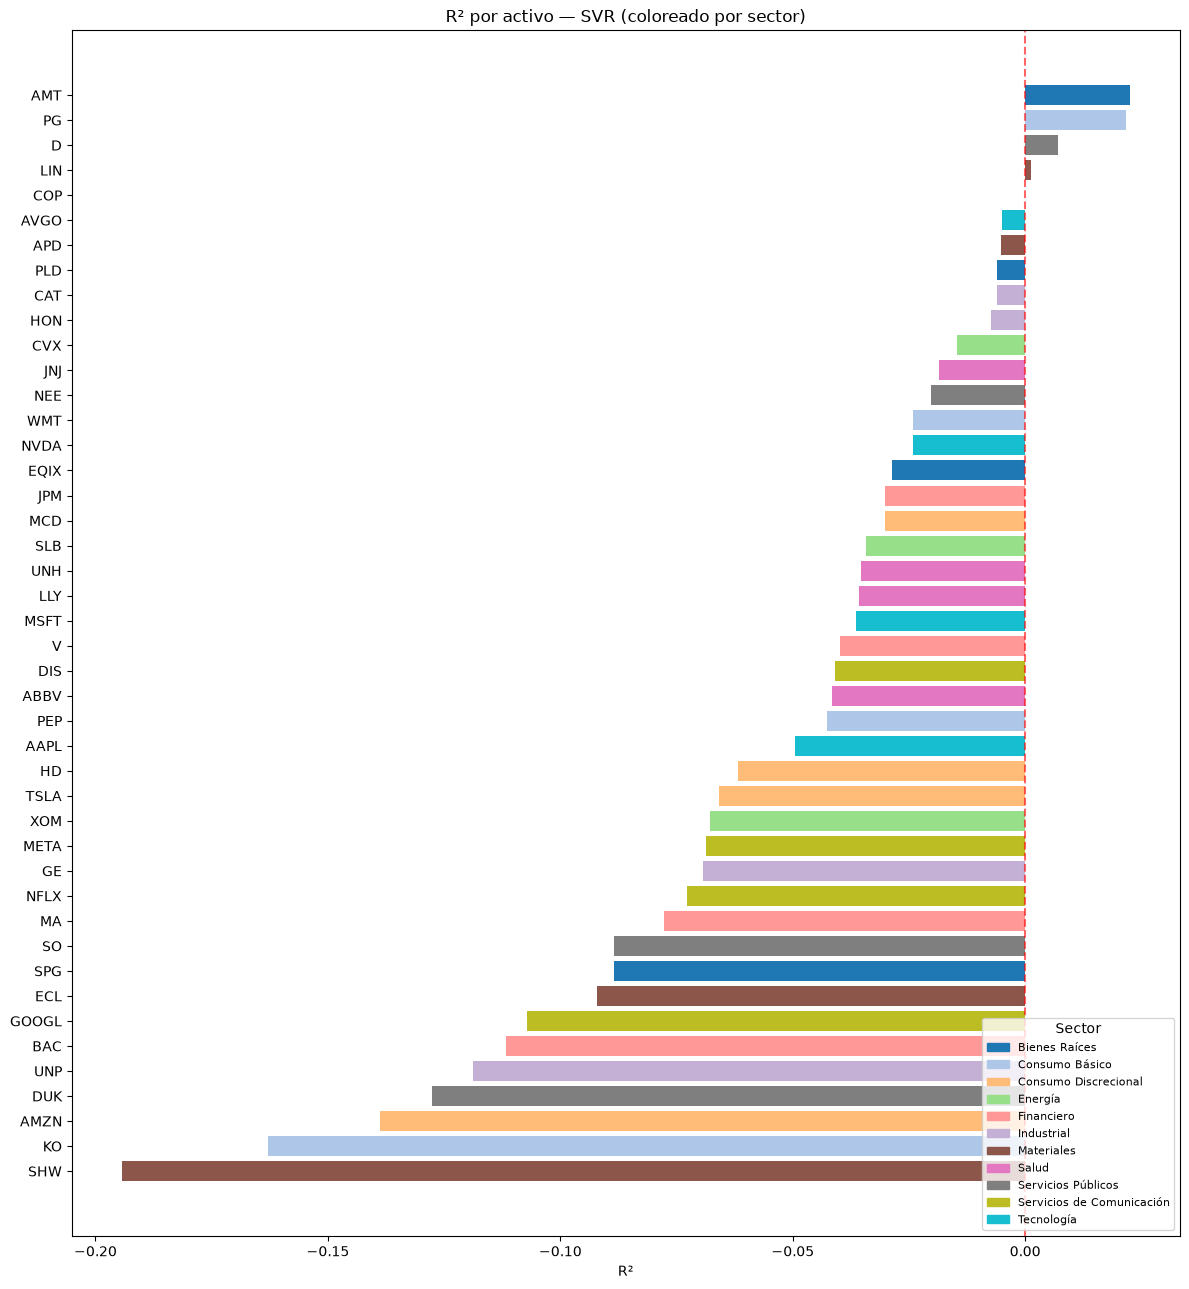

In [8]:
from matplotlib.patches import Patch

r2_sorted = results_df["R2"].sort_values()
bar_colors = [sector_to_color.get(ticker_to_sector.get(t, "Otro"), "gray") for t in r2_sorted.index]

fig, ax = plt.subplots(figsize=(12, 13))
ax.barh(r2_sorted.index, r2_sorted.values, color=bar_colors)
ax.axvline(0, color="red", linestyle="--", alpha=0.6)
ax.set_title("R² por activo — SVR (coloreado por sector)")
ax.set_xlabel("R²")

handles = [Patch(color=sector_to_color[s], label=s) for s in sectors]
ax.legend(handles=handles, loc="lower right", fontsize=8, title="Sector")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_r2_por_activo.png", dpi=300, bbox_inches="tight")
plt.show()


### R² promedio por sector

Pregunta propia de este experimento: ¿la capacidad predictiva de SVR cambia según el sector? Por ejemplo, sectores defensivos (Servicios Públicos, Consumo Básico) podrían ser más o menos predecibles que los más volátiles (Tecnología, Energía).

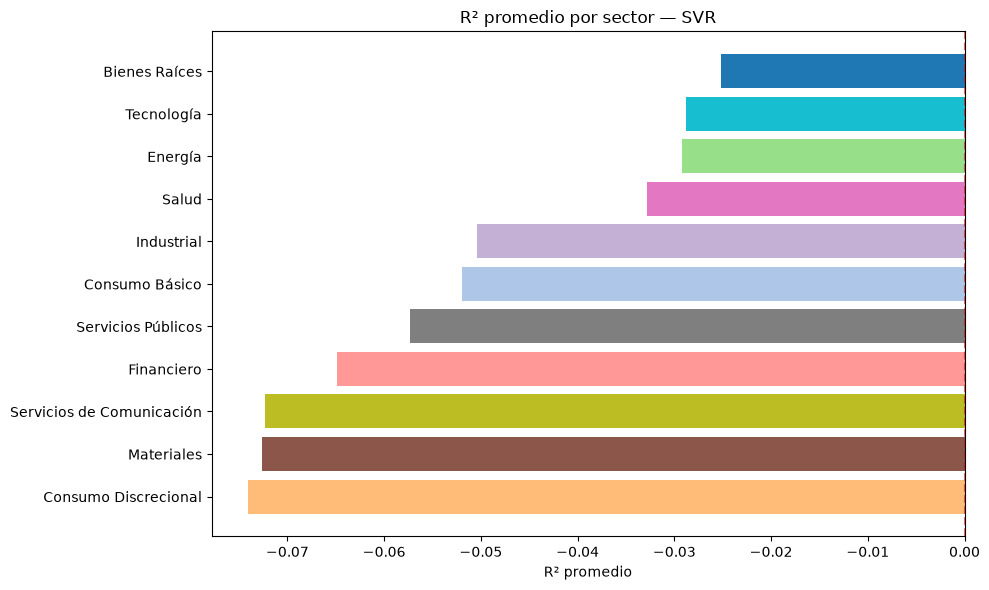

,mean,min,max,count
sector,,,,
Bienes Raíces,-0.0252,-0.0885,0.0225,4
Tecnología,-0.0288,-0.0495,-0.0050,4
Energía,-0.0292,-0.0678,-0.0001,4
Salud,-0.0328,-0.0416,-0.0186,4
Industrial,-0.0504,-0.1188,-0.0061,4
Consumo Básico,-0.0520,-0.1630,0.0216,4
Servicios Públicos,-0.0573,-0.1277,0.0071,4
Financiero,-0.0648,-0.1117,-0.0301,4
Servicios de Comunicación,-0.0724,-0.1071,-0.0409,4


In [9]:
r2_by_sector = (
    results_df.assign(sector=[ticker_to_sector.get(t, "Otro") for t in results_df.index])
    .groupby("sector")["R2"]
    .agg(["mean", "min", "max", "count"])
    .sort_values("mean", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(r2_by_sector.index, r2_by_sector["mean"], color=[sector_to_color[s] for s in r2_by_sector.index])
ax.axvline(0, color="red", linestyle="--", alpha=0.6)
ax.invert_yaxis()
ax.set_title("R² promedio por sector — SVR")
ax.set_xlabel("R² promedio")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01b_r2_por_sector.png", dpi=300, bbox_inches="tight")
plt.show()

r2_by_sector.round(4)


## Predicho vs. real — ejemplo visual (2-3 activos)

Para inspeccionar cualitativamente qué tan bien sigue el modelo al retorno real, más allá de la métrica agregada.

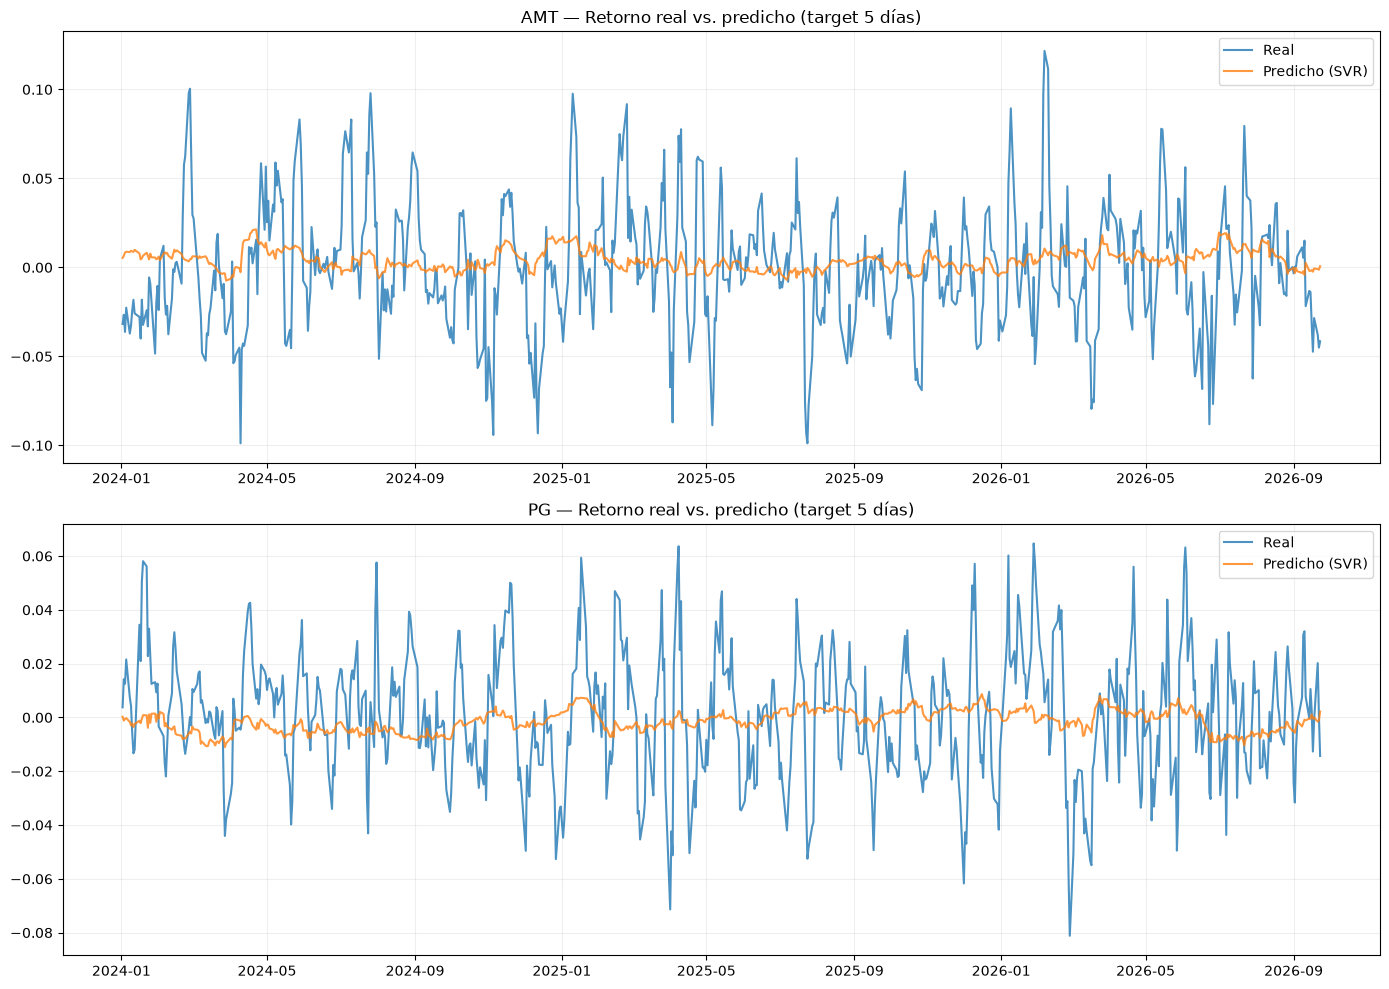

In [10]:
example_tickers = results_df.sort_values("R2", ascending=False).index[:2].tolist()

fig, axes = plt.subplots(len(example_tickers), 1, figsize=(14, 5 * len(example_tickers)))

if len(example_tickers) == 1:
    axes = [axes]

for ax, ticker in zip(axes, example_tickers):
    pred_df = predictions[ticker]
    ax.plot(pred_df["Date"], pred_df["actual"], label="Real", alpha=0.8)
    ax.plot(pred_df["Date"], pred_df["predicted"], label="Predicho (SVR)", alpha=0.8)
    ax.set_title(f"{ticker} — Retorno real vs. predicho (target 5 días)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_predicho_vs_real.png", dpi=300, bbox_inches="tight")
plt.show()


## Vector de retornos esperados (mu) predicho por SVR

Este es el insumo que reemplaza al `mu` histórico usado en Markowitz (Fase 5). Se calcula como el promedio de las predicciones del modelo en el conjunto de test, anualizado por **capitalización compuesta** (no multiplicación lineal), igual que hace internamente PyPortfolioOpt — así se evita amplificar de forma irreal cualquier sesgo pequeño de la predicción. El benchmark (`^GSPC`) se excluye porque Markowitz no invierte en el índice, solo lo usa como referencia.

In [11]:
PERIODS_PER_YEAR = 252 / 5  # el target es un retorno de 5 días

mu_svr = {}

for ticker, pred_df in predictions.items():
    mean_5d_return = pred_df["predicted"].mean()
    mu_svr[ticker] = (1 + mean_5d_return) ** PERIODS_PER_YEAR - 1

mu_svr = pd.Series(mu_svr, name="mu_svr").sort_values(ascending=False)

mu_svr


AVGO     0.759191
NVDA     0.702540
LLY      0.545498
V        0.457938
CAT      0.435766
UNH      0.426332
MA       0.396165
COP      0.296615
MSFT     0.279714
JPM      0.252132
PEP      0.241980
PLD      0.236433
AMT      0.220507
LIN      0.135042
DIS      0.088381
WMT      0.075617
MCD      0.036249
JNJ      0.033333
D        0.012972
CVX     -0.026688
EQIX    -0.040095
NEE     -0.056295
ABBV    -0.056529
PG      -0.070032
AAPL    -0.080255
HON     -0.086108
GE      -0.086497
SO      -0.109797
APD     -0.131725
GOOGL   -0.146653
SLB     -0.148426
ECL     -0.162580
NFLX    -0.169492
XOM     -0.190172
SPG     -0.194062
DUK     -0.196479
UNP     -0.198264
KO      -0.202581
TSLA    -0.204298
META    -0.205815
BAC     -0.252587
HD      -0.328264
AMZN    -0.348344
SHW     -0.368542
Name: mu_svr, dtype: float64

### Comparación: mu histórico (Fase 5) vs. mu predicho por SVR

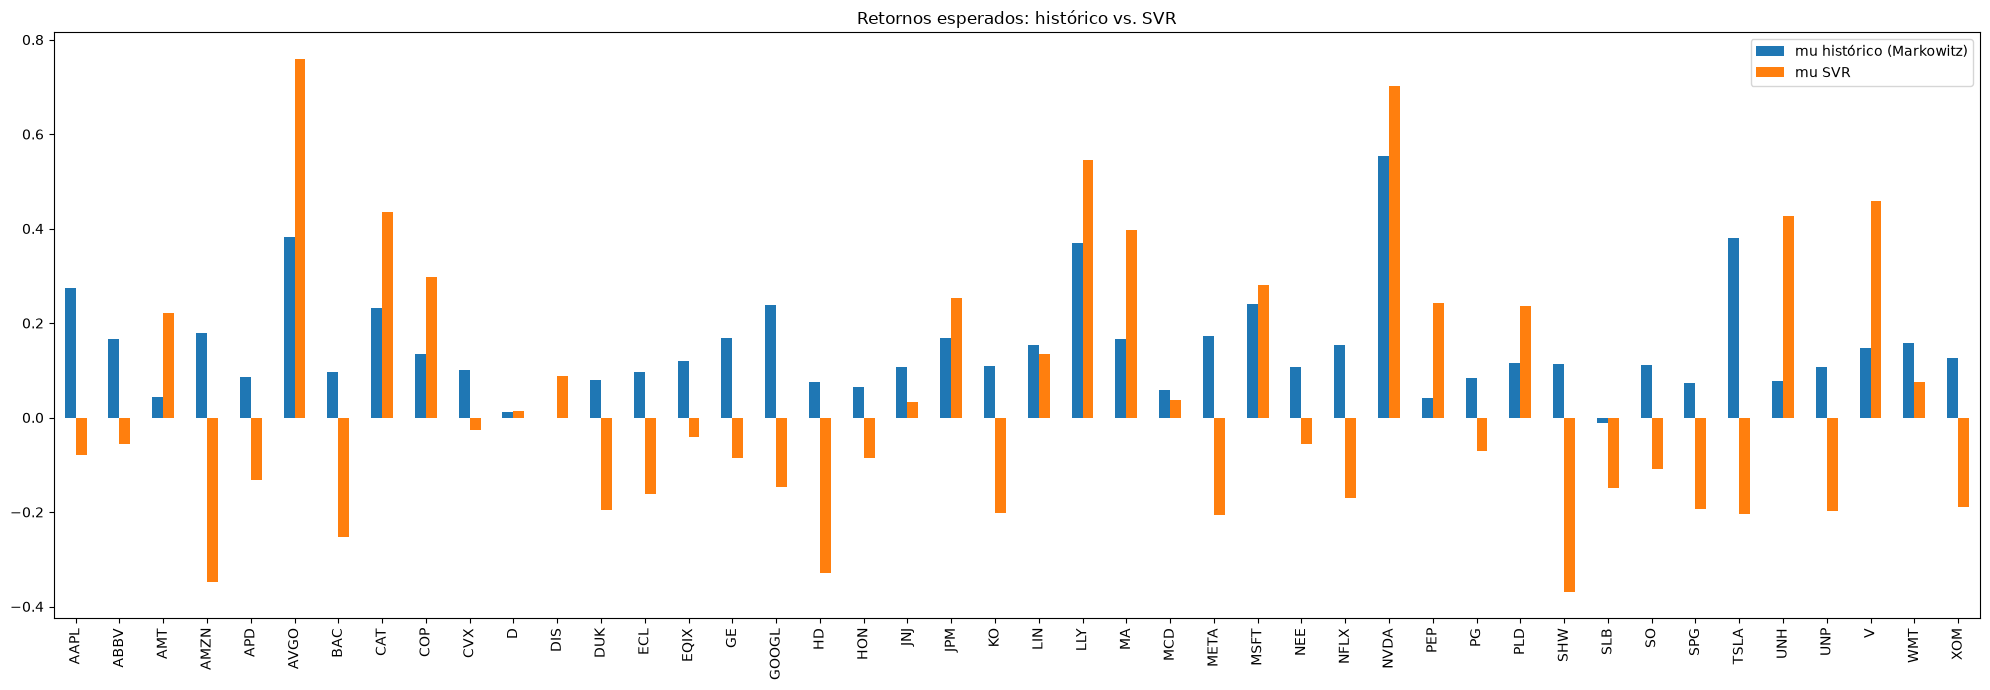

,mu histórico (Markowitz),mu SVR
AAPL,0.2743,-0.0803
ABBV,0.1666,-0.0565
AMT,0.0437,0.2205
AMZN,0.1786,-0.3483
APD,0.0869,-0.1317
AVGO,0.3813,0.7592
BAC,0.0965,-0.2526
CAT,0.2325,0.4358
COP,0.1341,0.2966
CVX,0.1016,-0.0267


In [12]:
from pypfopt.expected_returns import mean_historical_return

prices_for_mu = pd.read_csv(DATA_DIR / "adjusted_prices.csv", index_col=0, parse_dates=True)
asset_prices_svr = prices_for_mu.drop(columns=[benchmark])

mu_historical = mean_historical_return(asset_prices_svr)

mu_comparison = pd.DataFrame({
    "mu histórico (Markowitz)": mu_historical,
    "mu SVR": mu_svr
})

mu_comparison.plot(kind="bar", figsize=(20, 7), title="Retornos esperados: histórico vs. SVR")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_mu_historico_vs_svr.png", dpi=300, bbox_inches="tight")
plt.show()

mu_comparison.round(4)


## Guardar resultados

In [13]:
results_df.to_csv(RESULTS_DIR / "svr_performance_by_ticker.csv")
mu_svr.to_csv(RESULTS_DIR / "mu_svr.csv")

for ticker, pred_df in predictions.items():
    pred_df.to_csv(RESULTS_DIR / f"predictions_{ticker}.csv", index=False)

print("Resultados guardados en:", RESULTS_DIR)


Resultados guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\svr_diversified


## 10. Portafolio de Markowitz usando mu_svr (Opción 1: cuantificar el impacto)

Se corre la misma optimización de Máximo Sharpe de la Fase 5, pero reemplazando el `mu` histórico por `mu_svr`. El objetivo es cuantificar qué tan bien (o mal) le habría ido a un inversionista que hubiera confiado en las predicciones de SVR, comparado contra Markowitz clásico, Equal Weight y el S&P 500.

In [14]:
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

MAX_WEIGHT = 0.15  # misma restricción usada en la Fase 5, para comparar en igualdad de condiciones

S_shrink_svr = CovarianceShrinkage(asset_prices_svr).ledoit_wolf()

ef_svr = EfficientFrontier(mu_svr, S_shrink_svr, weight_bounds=(0, MAX_WEIGHT))

# Cota mínima: si un activo entra al portafolio, debe tener al menos 1% de peso
ef_svr.add_constraint(lambda w: w >= 0.01)
raw_weights_svr = ef_svr.max_sharpe(risk_free_rate=0.02)
weights_svr = ef_svr.clean_weights()

perf_svr = ef_svr.portfolio_performance(verbose=True, risk_free_rate=0.02)

pd.Series(weights_svr).sort_values(ascending=False)


Expected annual return: 35.9%
Annual volatility: 18.2%
Sharpe Ratio: 1.86


AVGO     0.15000
NVDA     0.15000
LLY      0.15000
CAT      0.10257
V        0.05743
UNH      0.01000
MA       0.01000
COP      0.01000
MSFT     0.01000
JPM      0.01000
PEP      0.01000
PLD      0.01000
AMT      0.01000
LIN      0.01000
DIS      0.01000
WMT      0.01000
MCD      0.01000
JNJ      0.01000
D        0.01000
CVX      0.01000
EQIX     0.01000
NEE      0.01000
ABBV     0.01000
PG       0.01000
AAPL     0.01000
HON      0.01000
GE       0.01000
SO       0.01000
APD      0.01000
GOOGL    0.01000
SLB      0.01000
ECL      0.01000
NFLX     0.01000
XOM      0.01000
SPG      0.01000
DUK      0.01000
UNP      0.01000
KO       0.01000
TSLA     0.01000
META     0.01000
BAC      0.01000
HD       0.01000
AMZN     0.01000
SHW      0.01000
dtype: float64

In [15]:
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

MAX_WEIGHT = 0.1  # misma restricción usada en la Fase 5, para comparar en igualdad de condiciones

S_shrink_svr_t = CovarianceShrinkage(asset_prices_svr).ledoit_wolf()

ef_svr_t = EfficientFrontier(mu_svr, S_shrink_svr_t, weight_bounds=(0, MAX_WEIGHT))

# Cota mínima: si un activo entra al portafolio, debe tener al menos 1% de peso
ef_svr_t.add_constraint(lambda w: w >= 0.01)
raw_weights_svr_t = ef_svr_t.max_sharpe(risk_free_rate=0.02)
weights_svr_t = ef_svr_t.clean_weights()

perf_svr_t = ef_svr_t.portfolio_performance(verbose=True, risk_free_rate=0.02)

pd.Series(weights_svr_t).sort_values(ascending=False)

Expected annual return: 31.7%
Annual volatility: 18.4%
Sharpe Ratio: 1.61


AVGO     0.10000
NVDA     0.10000
LLY      0.10000
V        0.10000
CAT      0.10000
MA       0.06945
UNH      0.03651
AMT      0.03404
MSFT     0.01000
JPM      0.01000
PEP      0.01000
COP      0.01000
PLD      0.01000
LIN      0.01000
DIS      0.01000
WMT      0.01000
MCD      0.01000
JNJ      0.01000
D        0.01000
CVX      0.01000
EQIX     0.01000
NEE      0.01000
ABBV     0.01000
PG       0.01000
AAPL     0.01000
HON      0.01000
GE       0.01000
SO       0.01000
APD      0.01000
GOOGL    0.01000
SLB      0.01000
ECL      0.01000
NFLX     0.01000
XOM      0.01000
SPG      0.01000
DUK      0.01000
UNP      0.01000
KO       0.01000
TSLA     0.01000
META     0.01000
BAC      0.01000
HD       0.01000
AMZN     0.01000
SHW      0.01000
dtype: float64

### Composición sectorial de los portafolios Markowitz + SVR

Agrupa los pesos óptimos por sector para ambas variantes (cota máxima 15% y 10%, con cota mínima de 1%) y los compara contra Equal Weight. Sirve para ver si SVR, al alimentar `mu` con predicciones, concentra el portafolio en pocos sectores.

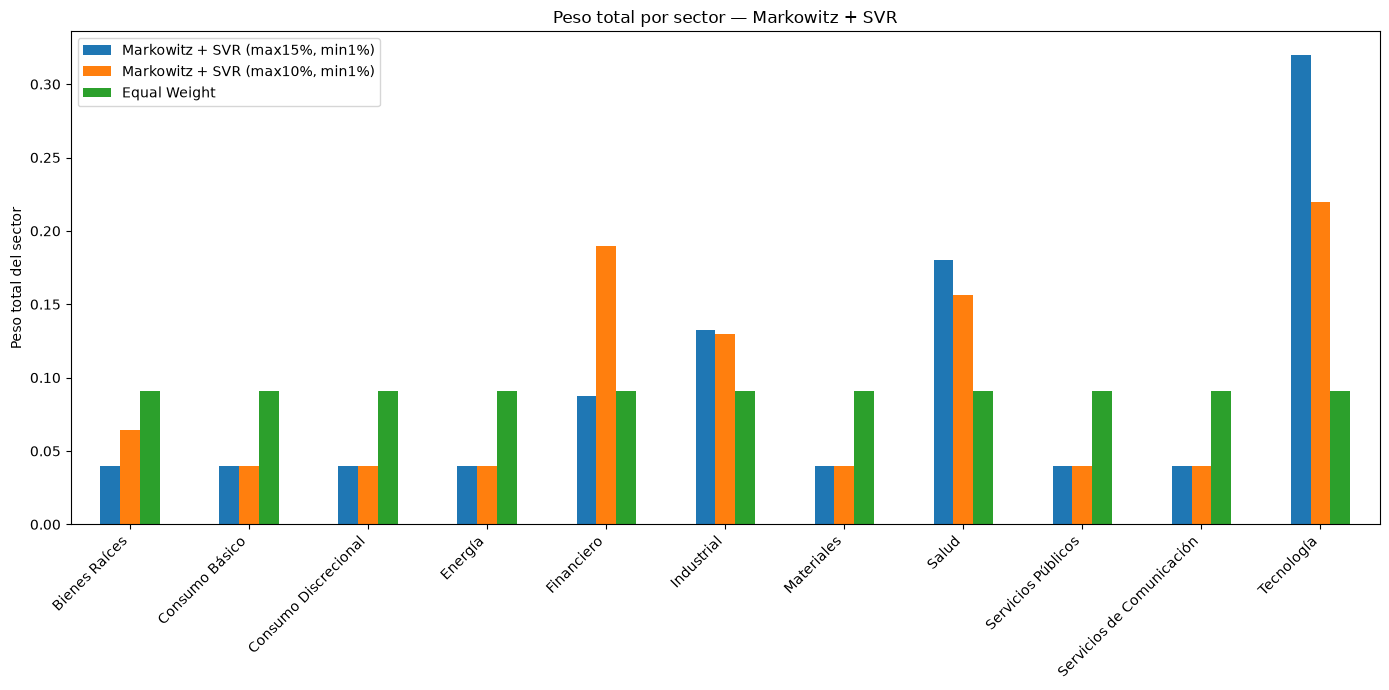

,"Markowitz + SVR (max15%, min1%)","Markowitz + SVR (max10%, min1%)",Equal Weight
Bienes Raíces,0.0400,0.0640,0.0909
Consumo Básico,0.0400,0.0400,0.0909
Consumo Discrecional,0.0400,0.0400,0.0909
Energía,0.0400,0.0400,0.0909
Financiero,0.0874,0.1894,0.0909
Industrial,0.1326,0.1300,0.0909
Materiales,0.0400,0.0400,0.0909
Salud,0.1800,0.1565,0.0909
Servicios Públicos,0.0400,0.0400,0.0909
Servicios de Comunicación,0.0400,0.0400,0.0909


In [16]:
weights_equal_sector = pd.Series(
    1 / len(asset_prices_svr.columns), index=asset_prices_svr.columns
).to_dict()

sector_weights_svr = pd.DataFrame({
    "Markowitz + SVR (max15%, min1%)": weights_by_sector(weights_svr),
    "Markowitz + SVR (max10%, min1%)": weights_by_sector(weights_svr_t),
    "Equal Weight": weights_by_sector(weights_equal_sector)
}).fillna(0)

sector_weights_svr.plot(kind="bar", figsize=(14, 7), title="Peso total por sector — Markowitz + SVR")
plt.ylabel("Peso total del sector")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "06_composicion_sectorial_svr.png", dpi=300, bbox_inches="tight")
plt.show()

sector_weights_svr.round(4)


### Backtest: Markowitz+SVR vs. Markowitz clásico, Equal Weight y S&P 500

Mismo periodo y misma lógica de backtest de pesos fijos sin rebalanceo que en la Fase 5, para que la comparación sea justa.

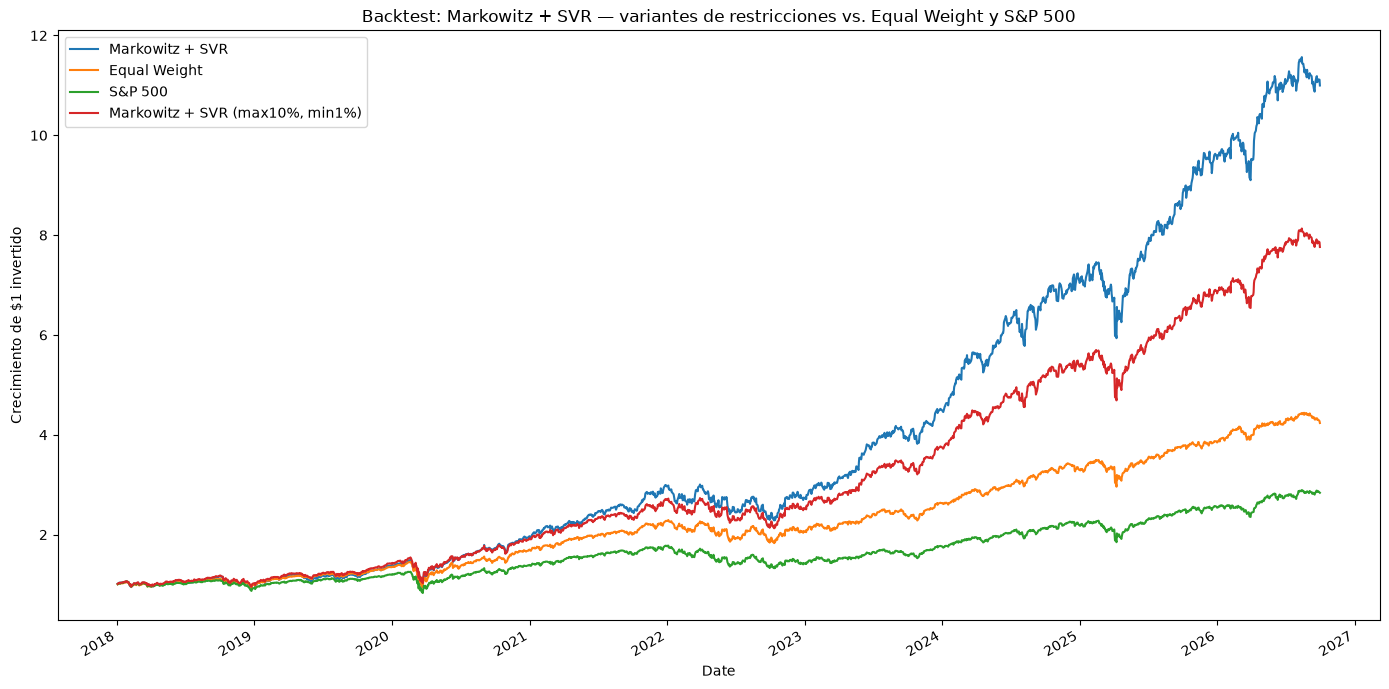

In [17]:
returns_for_backtest = pd.read_csv(DATA_DIR / "daily_returns.csv", index_col=0, parse_dates=True)
returns_for_backtest.index.name = "Date"
returns_for_backtest_clean = returns_for_backtest.dropna(how="all")

asset_returns_svr = returns_for_backtest_clean.drop(columns=[benchmark])

def portfolio_cumulative_return(weights: pd.Series, returns: pd.DataFrame) -> pd.Series:
    aligned_weights = weights.reindex(returns.columns).fillna(0)
    portfolio_returns = (returns * aligned_weights).sum(axis=1)
    return (1 + portfolio_returns).cumprod()

n_assets = len(asset_returns_svr.columns)
weights_equal_svr = pd.Series(1 / n_assets, index=asset_returns_svr.columns)

comparison_svr = pd.DataFrame({
    "Markowitz + SVR": portfolio_cumulative_return(pd.Series(weights_svr), asset_returns_svr),
    "Equal Weight": portfolio_cumulative_return(weights_equal_svr, asset_returns_svr),
    "S&P 500": (1 + returns_for_backtest_clean[benchmark]).cumprod()
})

# Agregar la variante (MAX_WEIGHT=0.10 + cota mínima 1%) a la comparación existente

comparison_svr["Markowitz + SVR (max10%, min1%)"] = portfolio_cumulative_return(
    pd.Series(weights_svr_t), asset_returns_svr
)

comparison_svr.plot(figsize=(14, 7), title="Backtest: Markowitz + SVR — variantes de restricciones vs. Equal Weight y S&P 500")
plt.ylabel("Crecimiento de $1 invertido")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "05_backtest_markowitz_svr_variantes.png", dpi=300, bbox_inches="tight")
plt.show()


### Tabla de métricas comparativa

Para tener la comparación completa, agrega manualmente la fila de **Markowitz clásico** con los valores que salgan en `04_markowitz_diversified.ipynb` (no uses los del universo original de 20 activos: aquí el universo es distinto).

In [18]:
def annualized_metrics(cum_returns: pd.Series, risk_free_rate: float = 0.02) -> dict:
    daily_returns = cum_returns.pct_change().dropna()
    ann_return = daily_returns.mean() * 252
    ann_vol = daily_returns.std() * np.sqrt(252)
    sharpe = (ann_return - risk_free_rate) / ann_vol
    max_drawdown = (cum_returns / cum_returns.cummax() - 1).min()
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe Ratio": sharpe,
        "Máximo Drawdown": max_drawdown
    }

summary_svr = pd.DataFrame({
    col: annualized_metrics(comparison_svr[col]) for col in comparison_svr.columns
}).T

summary_svr.round(4)

,Retorno anualizado,Volatilidad anualizada,Sharpe Ratio,Máximo Drawdown
Markowitz + SVR,0.2989,0.2246,1.2417,-0.3217
Equal Weight,0.1818,0.1826,0.8860,-0.3542
S&P 500,0.1374,0.1914,0.6133,-0.3392
"Markowitz + SVR (max10%, min1%)",0.2555,0.2078,1.1337,-0.3344


In [19]:
def annualized_metrics(cum_returns: pd.Series, risk_free_rate: float = 0.02) -> dict:
    daily_returns = cum_returns.pct_change().dropna()
    ann_return = daily_returns.mean() * 252
    ann_vol = daily_returns.std() * np.sqrt(252)
    sharpe = (ann_return - risk_free_rate) / ann_vol
    max_drawdown = (cum_returns / cum_returns.cummax() - 1).min()
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe Ratio": sharpe,
        "Máximo Drawdown": max_drawdown
    }

summary_svr_t = pd.DataFrame({
    col: annualized_metrics(comparison_svr[col]) for col in comparison_svr.columns
}).T

summary_svr_t.round(4)

,Retorno anualizado,Volatilidad anualizada,Sharpe Ratio,Máximo Drawdown
Markowitz + SVR,0.2989,0.2246,1.2417,-0.3217
Equal Weight,0.1818,0.1826,0.8860,-0.3542
S&P 500,0.1374,0.1914,0.6133,-0.3392
"Markowitz + SVR (max10%, min1%)",0.2555,0.2078,1.1337,-0.3344


### Guardar resultados de la Opción 1

In [20]:
pd.Series(weights_svr).to_csv(RESULTS_DIR / "weights_markowitz_svr.csv")
pd.Series(weights_svr_t).to_csv(RESULTS_DIR / "weights_markowitz_svr_max10.csv")
comparison_svr.to_csv(RESULTS_DIR / "backtest_markowitz_svr.csv")
summary_svr.to_csv(RESULTS_DIR / "summary_markowitz_svr.csv")

print("Resultados de Markowitz+SVR guardados en:", RESULTS_DIR)


Resultados de Markowitz+SVR guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\svr_diversified
